# FALCON H1: decoding 7-DoF velocity across days

This example trains two decoders on the six held-in days and scores them as FALCON does. The target is the velocity of the 7 DoFs (3 translation, 1 roll, 3 grasp). The score is R² over the 7 DoFs, weighted by their variance, on the samples `eval_mask` marks, computed per day and then averaged over days, separately for held-in and held-out days.

The held-out days are used zero-shot: no sample of theirs is used to train, normalize or select a model. Both decoders are causal, so a prediction uses no input after its sample, as FALCON requires.

FALCON keeps its own test samples on its evaluation server, for held-in and held-out days alike. The scores here come from the released files, so they are close to FALCON's setup but not on the same samples.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from neuralset.events.etypes import Event
from scipy.signal import lfilter
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset

import neuralshed
from neuralshed.datasets.karpowicz_2024_h1 import utils
from neuralshed.datasets.karpowicz_2024_h1.study import Karpowicz2024FalconH1
from neuralshed.datasets.utils import dataset_dir
from neuralshed.extractors import BehavioralSeriesExtractor
from neuralshed.extractors import NeuralFeatureExtractor

# 20 ms samples
FS = utils.BIN_RATE_HZ

# FALCON's target, the 7 DoFs in the order of utils.DOF_LABELS
VELOCITY_TYPES = (
    "LinearVelocitySeries",
    "AngularVelocitySeries",
    "GraspVelocitySeries",
)

# In each held-in recording, the last 20% of trials are the test and the 10% before them the validation.
TEST_FRACTION = 0.2
VALIDATION_FRACTION = 0.1

# FALCON's sample decoder: causal exponential filter with a 240 ms time constant
TAU_S = 0.24

# 1 s training windows that start every 0.5 s, in samples
WINDOW = 50
STRIDE = 25

# categorical colors, in fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
TRUTH_COLOR = "#3b3b3b"

torch.manual_seed(0)


def falcon_r2(recordings, predictions, part):
    """FALCON's score per day: R2 over the 7 DoFs, weighted by their variance, on the scored
    samples of ``part``, with the recordings of a day pooled."""
    pooled = {}
    for r in recordings:
        keep = r["scored"] & (r["part"] == part)
        if not keep.any():
            continue
        truth = r["velocity"][:, keep].T
        predicted = predictions[r["session"]][:, keep].T
        pooled.setdefault(r["falcon_day"], []).append((truth, predicted))

    scores = {}
    for day, pairs in pooled.items():
        truth = np.concatenate([t for t, _ in pairs])
        predicted = np.concatenate([p for _, p in pairs])
        scores[day] = r2_score(truth, predicted, multioutput="variance_weighted")
    return pd.Series(scores)


def smooth(neural):
    """Causal exponential filter along time, as in FALCON's sample decoder."""
    lags = np.arange(0.0, TAU_S, 1 / FS)
    kernel = np.exp(-lags / TAU_S)
    kernel /= kernel.sum()
    return lfilter(kernel, [1.0], neural, axis=1)


def masked_mse(prediction, reference, weights):
    """MSE over the samples where ``weights`` is 1."""
    error = ((prediction - reference) ** 2 * weights).sum()
    return error / (weights.sum() * reference.shape[1]).clamp(min=1.0)


def windows(array, end):
    """(channels, samples) -> (n_windows, channels, WINDOW), from the first ``end`` samples."""
    tensor = torch.as_tensor(array[:, :end], dtype=torch.float32)
    return tensor.unfold(-1, WINDOW, STRIDE).permute(1, 0, 2)


# Path to your .env (see .env.example). Delete this if the variables are already exported.
ENV_FILE = Path("../../../../.env")

# Arguments override the file, e.g. data_root="/path/to/data". Keep tokens in .env.
neuralshed.configure(
    env_file=ENV_FILE,
    data_root=None,
)

root = dataset_dir("karpowicz_2024_h1") / "data"
s = Karpowicz2024FalconH1(path=root)

s.download()

neuralshed: NEURALSHED_DATA_ROOT is not set. Export it, or call neuralshed.configure(env_file=...) or neuralshed.configure(data_root=...).


2026-11-12 18:56:32 - INFO - neuralset.events.study:473 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1.


2026-11-12 18:56:32 - INFO - neuralset.events.study:88 - Permissions set for /Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1 (skipped 0 non-owned items).


neuralshed data root: /Volumes/seagate_0/tether/datasets (from /Users/luiztauffer/Github/tether_scratch/.env)


## 1. Recordings and FALCON days

The Study has 27 recordings: 13 held-in-calib over 6 days and 14 held-out-calib over 7 days. FALCON numbers the days in date order, `S0` to `S12`, and scores a day with its recordings pooled.

In [2]:
events = s.run()

timelines = events.loc[events.type == "SpikeCounts", ["session", "original_split", "duration"]]
dates = sorted(timelines.session.str[:8].unique())
falcon_day = {date: f"S{index}" for index, date in enumerate(dates)}
timelines["falcon_day"] = timelines.session.str[:8].map(falcon_day)

days = timelines.groupby("falcon_day", sort=False).agg(
    split=("original_split", "first"),
    recordings=("session", "size"),
    minutes=("duration", lambda d: round(d.sum() / 60, 1)),
)
print(days.to_string())

                     split  recordings  minutes
falcon_day                                     
S0           held-in-calib           2      5.8
S1           held-in-calib           3      8.5
S2           held-in-calib           2      7.8
S3           held-in-calib           2      7.4
S4           held-in-calib           2      8.0
S5           held-in-calib           2      7.8
S6          held-out-calib           2      1.6
S7          held-out-calib           2      1.7
S8          held-out-calib           2      1.6
S9          held-out-calib           2      1.6
S10         held-out-calib           2      1.6
S11         held-out-calib           2      1.6
S12         held-out-calib           2      1.8


## 2. Whole recordings, one segment each

A `Segmenter` triggered on the whole-recording `SpikeCounts` row with no `duration` gives one segment per recording, spanning the trigger row. `NeuralFeatureExtractor` reads the 176 channels of threshold-crossing counts, and three `BehavioralSeriesExtractor`s read the linear, angular and grasp velocity, stacked into the 7 DoFs. No extractor reads masks yet, so the `BinaryMask` row of each recording is read with `Event.read()`.

In [3]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            event_types="SpikeCounts",
            target_unit="native",
            frequency=FS,
        ),
        **{
            name: BehavioralSeriesExtractor(
                event_types=name,
                frequency=FS,
            )
            for name in VELOCITY_TYPES
        },
    },
    trigger_query="type == 'SpikeCounts'",
    duration=None,
)
segments = segmenter.apply(events)
segments.prepare()

masks = {
    row.timeline: Event.from_dict(row.to_dict()).read()[0].astype(bool)
    for _, row in events[events.type == "BinaryMask"].iterrows()
}

recordings = []
for index in range(len(segments)):
    batch = segments[index]
    trigger = batch.triggers.iloc[0]
    recordings.append(
        dict(
            session=trigger.session,
            timeline=trigger.timeline,
            split=trigger.original_split,
            falcon_day=falcon_day[trigger.session[:8]],
            neural=batch.data["neural"][0].numpy(),
            velocity=np.concatenate([batch.data[name][0].numpy() for name in VELOCITY_TYPES]),
            scored=masks[trigger.timeline],
        )
    )

first = recordings[0]
print("recordings:", len(recordings))
print("neural:", first["neural"].shape, " velocity:", first["velocity"].shape, " scored:", first["scored"].shape)

2026-11-12 18:56:33 - INFO - neuralset.dataloader:233 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/27 [00:00<?, ?it/s]

 11%|█         | 3/27 [00:00<00:01, 21.25it/s]

 26%|██▌       | 7/27 [00:00<00:00, 30.01it/s]

 41%|████      | 11/27 [00:00<00:00, 33.81it/s]

 56%|█████▌    | 15/27 [00:00<00:00, 27.95it/s]

... (21 outputs left out)

 67%|██████▋   | 18/27 [00:00<00:00, 54.27it/s]

 89%|████████▉ | 24/27 [00:00<00:00, 54.53it/s]

100%|██████████| 27/27 [00:00<00:00, 54.59it/s]

recordings: 27
neural: (176, 10819)  velocity: (7, 10819)  scored: (10819,)


## 3. Split each held-in recording by trial

Neighboring samples of a trial are alike, so a trial must sit in one part only. The phase rows carry `trial_id`, and each trial starts at its first phase. In each held-in recording, the last 20% of trials (rounded) are the held-in test and the 10% before them (at least one trial) select the model. The trials before those train it. A 15-trial recording splits 10/2/3, an 8-trial one 5/1/2. Every held-out recording is a test, used zero-shot.

In [4]:
phases = events[events.trial_id.notna()]
trial_starts = phases.groupby(["timeline", "trial_id"]).start.min()

for r in recordings:
    r["part"] = np.full(len(r["scored"]), "held_out", dtype="<U10")
    if r["split"] != "held-in-calib":
        continue

    starts = np.sort(trial_starts[r["timeline"]].to_numpy())
    n_test = round(TEST_FRACTION * len(starts))
    n_validation = max(1, round(VALIDATION_FRACTION * len(starts)))
    validation_start = round(starts[-n_test - n_validation] * FS)
    test_start = round(starts[-n_test] * FS)

    r["part"][:] = "train"
    r["part"][validation_start:test_start] = "validation"
    r["part"][test_start:] = "test"

for part in ("train", "validation", "test", "held_out"):
    samples = sum(int((r["scored"] & (r["part"] == part)).sum()) for r in recordings)
    print(f"{part:>10}: {samples / FS / 60:5.1f} min scored")

     train:  29.4 min scored
validation:   5.5 min scored
      test:   9.3 min scored
  held_out:  11.2 min scored


## 4. Ridge baseline

FALCON's sample decoder (`decoder_demos/sklearn_decoder.py` in [falcon-challenge](https://github.com/snel-repo/falcon-challenge)) smooths each channel with a causal exponential filter (240 ms time constant), z-scores it and fits a ridge regression from the 176 smoothed channels to the 7 velocities. Here the z-score uses the training trials only, the ridge is fit on their scored samples, and the regularization is the one of FALCON's 20 values (1e-5 to 1e5) that scores best on the validation trials.

In [5]:
for r in recordings:
    r["smoothed"] = smooth(r["neural"])

train_smoothed = np.concatenate([r["smoothed"][:, r["part"] == "train"] for r in recordings], axis=1)
smoothed_mean = train_smoothed.mean(axis=1, keepdims=True)
smoothed_std = train_smoothed.std(axis=1, keepdims=True)

# Channel 66 is silent in every recording.
smoothed_std[smoothed_std == 0] = 1.0

features = {r["session"]: ((r["smoothed"] - smoothed_mean) / smoothed_std).T for r in recordings}

train_x = np.concatenate([features[r["session"]][r["scored"] & (r["part"] == "train")] for r in recordings])
train_y = np.concatenate([r["velocity"][:, r["scored"] & (r["part"] == "train")].T for r in recordings])

best_score = -np.inf
for alpha in np.logspace(-5, 5, 20):
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_x, train_y)
    predictions = {session: ridge.predict(x).T for session, x in features.items()}
    score = falcon_r2(recordings, predictions, "validation").mean()
    if score > best_score:
        best_score = score
        best_alpha = alpha
        ridge_predictions = predictions

print(f"training samples: {len(train_x):,}")
print(f"alpha {best_alpha:.3g}, validation R2 {best_score:.3f}")

training samples: 88,333
alpha 8.86e+03, validation R2 0.210


## 5. Windows for a causal decoder

The decoder trains on 1 s windows that start every 0.5 s, cut from the training trials of each held-in recording, which come first in the recording. Spike counts are z-scored per channel with training statistics. The velocity is divided by one constant for all 7 DoFs, which keeps their relative scale, so the loss weights each DoF by its variance as FALCON's R² does. Translation holds a small share of that variance (printed below), so it weighs little in both. The loss counts only the samples `eval_mask` marks.

In [6]:
train_neural = np.concatenate([r["neural"][:, r["part"] == "train"] for r in recordings], axis=1)
neural_mean = train_neural.mean(axis=1, keepdims=True)
neural_std = train_neural.std(axis=1, keepdims=True)
neural_std[neural_std == 0] = 1.0

velocity_scale = float(train_y.std())

variance = train_y.var(axis=0)
share = pd.Series(variance / variance.sum(), index=list(utils.DOF_LABELS))
print("share of the velocity variance:")
print(share.round(3).to_string())
print()

x_windows = []
y_windows = []
mask_windows = []
for r in recordings:
    # The training trials are the first part of a held-in recording.
    train_end = int((r["part"] == "train").sum())
    if train_end == 0:
        continue
    x_windows.append(windows((r["neural"] - neural_mean) / neural_std, train_end))
    y_windows.append(windows(r["velocity"] / velocity_scale, train_end))
    mask_windows.append(windows(r["scored"][None].astype(np.float32), train_end))

x_train = torch.cat(x_windows)
y_train = torch.cat(y_windows)
mask_train = torch.cat(mask_windows)
print("neural:", tuple(x_train.shape), " velocity:", tuple(y_train.shape), " mask:", tuple(mask_train.shape))

share of the velocity variance:
tx    0.003
ty    0.009
tz    0.011
rx    0.117
g1    0.290
g2    0.306
g3    0.262

neural: (3609, 176, 50)  velocity: (3609, 7, 50)  mask: (3609, 1, 50)


## 6. A small causal convolutional decoder

The decoder maps `(B, 176, T)` to `(B, 7, T)`, one velocity per 20 ms sample. Each convolution is padded on the left only, so the output at a sample uses input up to that sample and none after it. Being convolutional, it runs on a whole recording as well as on a window, which is how the validation and test recordings are decoded: from the recording's start, as FALCON's server streams them.

In [7]:
class CausalDecoder(nn.Module):
    def __init__(self, n_in, n_out, hidden=128, kernel=9, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConstantPad1d((kernel - 1, 0), 0.0),
            nn.Conv1d(n_in, hidden, kernel),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.ConstantPad1d((kernel - 1, 0), 0.0),
            nn.Conv1d(hidden, hidden, kernel),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, n_out, 1),
        )

    def forward(self, x):
        return self.net(x)

    def decode(self, recordings):
        """Velocity of every sample of each whole recording, in source units."""
        self.eval()
        decoded = {}
        with torch.no_grad():
            for r in recordings:
                x = torch.as_tensor((r["neural"] - neural_mean) / neural_std, dtype=torch.float32)
                decoded[r["session"]] = self(x[None])[0].numpy() * velocity_scale
        return decoded


model = CausalDecoder(x_train.shape[1], y_train.shape[1])

## 7. Train

After each epoch, the held-in recordings are decoded whole and FALCON's score is computed on the validation trials. The weights of the best epoch are kept.

In [8]:
loader = DataLoader(
    TensorDataset(x_train, y_train, mask_train),
    batch_size=64,
    shuffle=True,
)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)
held_in = [r for r in recordings if r["split"] == "held-in-calib"]

best_score = -np.inf
for epoch in range(20):
    model.train()
    for xb, yb, mb in loader:
        optimizer.zero_grad()
        masked_mse(model(xb), yb, mb).backward()
        optimizer.step()

    score = falcon_r2(held_in, model.decode(held_in), "validation").mean()
    if score > best_score:
        best_score = score
        best_epoch = epoch + 1
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if (epoch + 1) % 5 == 0:
        print(f"epoch {epoch + 1:2d}  validation R2 {score:.3f}  (best {best_score:.3f})")

model.load_state_dict(best_state)
cnn_predictions = model.decode(recordings)
print(f"kept epoch {best_epoch}")

epoch  5  validation R2 0.565  (best 0.565)


epoch 10  validation R2 0.559  (best 0.565)


epoch 15  validation R2 0.557  (best 0.565)


epoch 20  validation R2 0.545  (best 0.565)


kept epoch 5


## 8. FALCON's score on held-in and held-out days

Held-in is scored on the test trials of the six held-in days, held-out on all scored samples of the seven held-out days. As on FALCON's leaderboard, the table gives the mean and standard deviation over days.

In [9]:
per_day = pd.DataFrame(
    {
        "ridge": pd.concat(
            [
                falcon_r2(recordings, ridge_predictions, "test"),
                falcon_r2(recordings, ridge_predictions, "held_out"),
            ]
        ),
        "causal CNN": pd.concat(
            [
                falcon_r2(recordings, cnn_predictions, "test"),
                falcon_r2(recordings, cnn_predictions, "held_out"),
            ]
        ),
    }
)
held_out_days = per_day.index.isin(timelines.loc[timelines.original_split == "held-out-calib", "falcon_day"])

summary = pd.DataFrame(
    {
        "held-in R2": per_day[~held_out_days].mean(),
        "held-in std": per_day[~held_out_days].std(ddof=0),
        "held-out R2": per_day[held_out_days].mean(),
        "held-out std": per_day[held_out_days].std(ddof=0),
    }
)
print(summary.round(2).to_string())

            held-in R2  held-in std  held-out R2  held-out std
ridge             0.22         0.02         0.02          0.07
causal CNN        0.54         0.07         0.11          0.07


### R² per day

Both decoders score lower on every held-out day than on any held-in day, the instability across days that FALCON is built to measure.

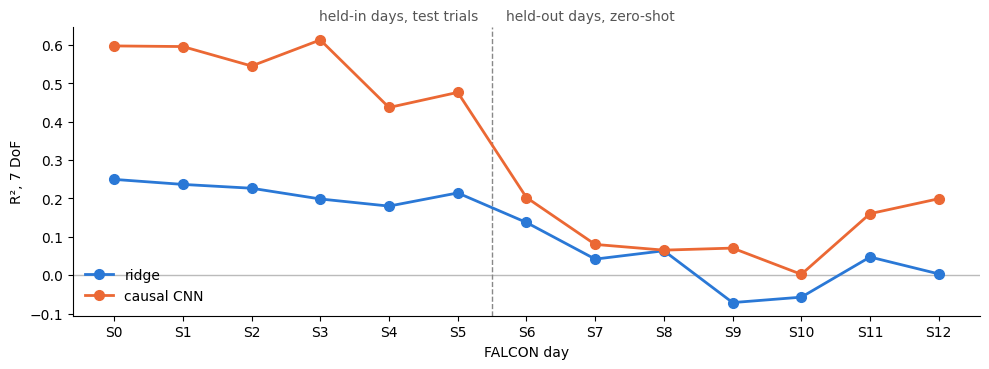

In [10]:
positions = np.arange(len(per_day))
boundary = int(np.flatnonzero(held_out_days)[0]) - 0.5

figure, ax = plt.subplots(figsize=(10, 3.8))
ax.axhline(0.0, color="#bbbbbb", lw=1)
ax.axvline(boundary, color="#888888", lw=1, ls="--")
for color, name in zip(COLORS, per_day.columns):
    ax.plot(positions, per_day[name], marker="o", ms=7, lw=2, color=color, label=name)

top = per_day.to_numpy().max() + 0.08
ax.text(boundary - 0.2, top, "held-in days, test trials", ha="right", va="top", color="#555555")
ax.text(boundary + 0.2, top, "held-out days, zero-shot", ha="left", va="top", color="#555555")
ax.set_xticks(positions, per_day.index)
ax.set_xlabel("FALCON day")
ax.set_ylabel("R², 7 DoF")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()

### Decoded and true velocity, last held-in day and first held-out day

On the left, the test trials of `19250120_block2`, on the last held-in day (`S5`). On the right, `19250126_block1`, FALCON's `S6_set_1`, the first held-out recording, decoded zero-shot. One DoF per group is shown, and the gaps are samples `eval_mask` leaves out. The CNN leaves `ty` near zero on both days, since translation weighs little in its loss.

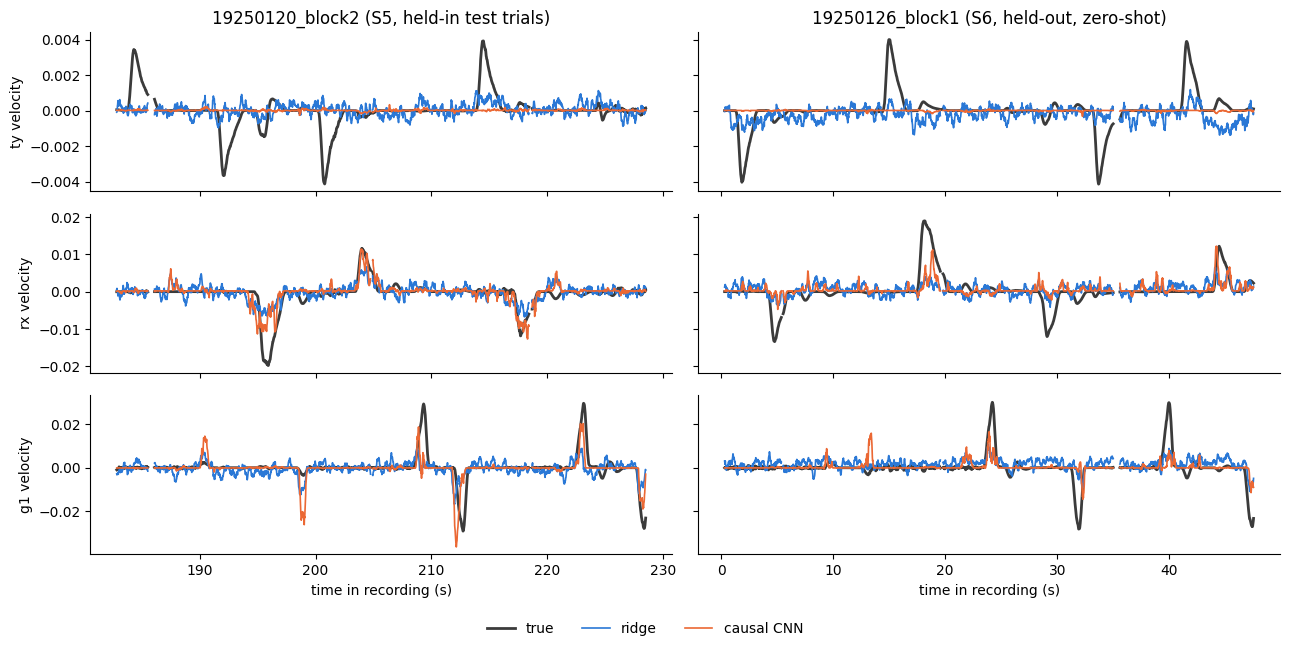

In [11]:
PANELS = (
    ("19250120_block2", "test", "S5, held-in test trials"),
    ("19250126_block1", "held_out", "S6, held-out, zero-shot"),
)
DOFS = ("ty", "rx", "g1")

figure, axes = plt.subplots(len(DOFS), len(PANELS), figsize=(13, 6.5), sharex="col", sharey="row")
for column, (session, part, title) in enumerate(PANELS):
    r = next(r for r in recordings if r["session"] == session)
    shown = np.flatnonzero(r["part"] == part)
    keep = r["scored"][shown]
    time = shown / FS
    curves = (
        ("true", r["velocity"], TRUTH_COLOR, 2.0),
        ("ridge", ridge_predictions[session], COLORS[0], 1.2),
        ("causal CNN", cnn_predictions[session], COLORS[1], 1.2),
    )

    axes[0, column].set_title(f"{session} ({title})")
    axes[-1, column].set_xlabel("time in recording (s)")
    for row, label in enumerate(DOFS):
        ax = axes[row, column]
        dof = utils.DOF_LABELS.index(label)
        for name, values, color, width in curves:
            ax.plot(time, np.where(keep, values[dof, shown], np.nan), color=color, lw=width, label=name)
        ax.spines[["top", "right"]].set_visible(False)
        if column == 0:
            ax.set_ylabel(f"{label} velocity")

handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncols=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))

## Takeaways

On the test trials of the held-in days, the causal CNN reaches an R² of 0.54 ± 0.07 and the ridge 0.22 ± 0.02 (mean ± std over days). On the held-out days, decoded zero-shot, they fall to 0.11 ± 0.07 and 0.02 ± 0.07. The CNN is one run with seed 0, and its scores move by a few hundredths with the seed and the number of training epochs. Grasp holds 86% of the velocity variance, roll 12% and translation 2% (section 5), so both scores mostly reflect grasp, and the CNN barely decodes translation.

For H1, Table 1 of the [FALCON paper](https://proceedings.neurips.cc/paper_files/paper/2024/hash/8c2e6bb15be1894b8fb4e0f9bcad1739-Abstract-Datasets_and_Benchmarks_Track.html) reports:

| decoder | held-out R² | held-in R² |
|---|---|---|
| Wiener filter trained on each day's own data | 0.21 ± 0.04 | 0.24 |
| zero-shot Wiener filter | 0.16 ± 0.03 | 0.20 |
| zero-shot RNN | 0.09 ± 0.18 | 0.31 |
| NDT2 Multi, few-shot recalibration | 0.52 ± 0.04 | 0.62 |

Those scores come from FALCON's withheld samples. FALCON's Wiener filter also uses 30 samples (600 ms) of history, and its zero-shot decoders are trained on one held-in day, so the comparison is approximate. The held-in ridge falls in the range of FALCON's Wiener filters, and both decoders lose most of their accuracy on the held-out days, as in FALCON.